# Operations, Monitoring & Evidence 
## Stage 4 · serve → containerise → automate → monitor → retrain → govern  <font color="red">[25 marks]</font>

- Each stage lists its **sub-tasks as a checklist**
- Implement reusable logic in `app.py`, `src/monitoring.py` and `src/retrain.py`.

**File ownership** —
- *Provided:* `src/generate_current_batch.py`, `src/evaluate.py`, `tests/`, `Dockerfile`, `.github/workflows/ci.yml`, `requirements.txt`
- *You create/extend:* `app.py`, `src/monitoring.py`, `src/retrain.py` and the cells below. 
- Run after the Stage-3 notebook.

## Stage 4.1 — API Deployment <font color="red">[5 marks]</font>

- **4.1.1 — FastAPI inference service (/predict + /health + validation) [3]** *(graded from `app.py`)* — POST `/predict` (probability + label) with request validation + missing-field handling, and GET `/health`.
- **4.1.2 — Live request/response demonstrated in-notebook [2]** *(graded from this notebook)* — call `/health` and `/predict` via `fastapi.testclient.TestClient` and show the JSON.

In [1]:
# TODO 4.1.1 (app.py): FastAPI with GET /health + POST /predict, loading the model from
#   artifacts/registry, with request validation + missing-field handling.
# TODO 4.1.2 (here): use TestClient to call /health and /predict; show the responses.

# ===== SOLUTION START =====
import json
import warnings
from pathlib import Path

import pandas as pd
from fastapi.testclient import TestClient

warnings.filterwarnings('ignore')

import config as cfg
from app import app

ART = cfg.ARTIFACT_DIR
EVIDENCE = ART / 'evidence'
EVIDENCE.mkdir(parents=True, exist_ok=True)

client = TestClient(app)


def browser_screenshot(url, out_path, width=1500, height=900, full_page=False, prepare=None):
    """Screenshot a page with Playwright (drives the local Edge/Chrome; dev-only tool).

    Runs in a worker thread because the sync Playwright API cannot run on Jupyter's
    asyncio loop. Returns the Path written, or None if Playwright is unavailable.
    """
    try:
        from playwright.sync_api import sync_playwright
    except ImportError:
        print('playwright not installed - screenshot skipped:', url)
        return None
    from concurrent.futures import ThreadPoolExecutor

    def shoot():
        with sync_playwright() as pw:
            browser = None
            for channel in ('msedge', 'chrome', None):
                try:
                    browser = (pw.chromium.launch(channel=channel) if channel
                               else pw.chromium.launch())
                    break
                except Exception:
                    continue
            page = browser.new_page(viewport={'width': width, 'height': height})
            page.goto(url)
            page.wait_for_timeout(4000)
            if prepare:
                prepare(page)
            page.screenshot(path=str(out_path), full_page=full_page)
            browser.close()
        return Path(out_path)

    with ThreadPoolExecutor(max_workers=1) as pool:
        return pool.submit(shoot).result()


# -----------------------------------------------------------------------------
# 4.1.2  GET /health
# -----------------------------------------------------------------------------
health = client.get('/health')
print('GET /health ->', health.status_code)
print(json.dumps(health.json(), indent=2))

# -----------------------------------------------------------------------------
# 4.1.2  POST /predict — a complete encounter taken from the training reference
# -----------------------------------------------------------------------------
columns = json.loads((ART / 'input_columns.json').read_text())
reference = pd.read_csv(ART / 'reference_sample.csv')

full_record = reference.iloc[0].where(pd.notna(reference.iloc[0]), None).to_dict()
full_resp = client.post('/predict', json={'features': full_record})

print('\nPOST /predict (complete record) ->', full_resp.status_code)
print(json.dumps(full_resp.json(), indent=2))

# -----------------------------------------------------------------------------
# 4.1.1  missing-field handling — send only 6 of the training columns
# -----------------------------------------------------------------------------
partial_record = {
    k: full_record[k]
    for k in columns[:6]
    if k in full_record
}
partial_resp = client.post('/predict', json={'features': partial_record})

print(f"\nPOST /predict (partial record, {len(partial_record)} of "
      f"{len(columns)} columns) -> {partial_resp.status_code}")
print(json.dumps(partial_resp.json(), indent=2))

# -----------------------------------------------------------------------------
# 4.1.1  request validation — empty payload and a negative counter must be 422
# -----------------------------------------------------------------------------
empty_resp = client.post('/predict', json={'features': {}})
print('\nPOST /predict (empty features) ->', empty_resp.status_code)
print('  detail:', empty_resp.json().get('detail'))

bad_record = dict(full_record)
bad_record['time_in_hospital'] = -5
bad_resp = client.post('/predict', json={'features': bad_record})
print('POST /predict (time_in_hospital=-5) ->', bad_resp.status_code)
print('  detail:', bad_resp.json().get('detail'))

schema_resp = client.post('/predict', json={'not_features': {}})
print('POST /predict (missing "features" key) ->', schema_resp.status_code)

# -----------------------------------------------------------------------------
# Evidence capture (requirement 9): request/response examples
# -----------------------------------------------------------------------------
examples = {
    'health': {'request': 'GET /health',
               'status': health.status_code,
               'response': health.json()},
    'predict_full': {'request': 'POST /predict',
                     'n_fields_sent': len(full_record),
                     'status': full_resp.status_code,
                     'response': full_resp.json()},
    'predict_partial': {'request': 'POST /predict',
                        'n_fields_sent': len(partial_record),
                        'status': partial_resp.status_code,
                        'response': partial_resp.json()},
    'validation_empty': {'status': empty_resp.status_code,
                         'response': empty_resp.json()},
    'validation_negative': {'status': bad_resp.status_code,
                            'response': bad_resp.json()},
    'validation_schema': {'status': schema_resp.status_code},
}
(EVIDENCE / 'api_examples.json').write_text(json.dumps(examples, indent=2))
(EVIDENCE / 'sample_request.json').write_text(
    json.dumps({'features': full_record}, indent=2, default=str)
)

# -----------------------------------------------------------------------------
# Independent validation of the API component (requirement 8)
# -----------------------------------------------------------------------------
checks = [
    ('GET /health returns 200', health.status_code == 200),
    ('health reports model_loaded=True', health.json().get('model_loaded') is True),
    ('POST /predict returns 200', full_resp.status_code == 200),
    ('probability in [0, 1]',
     0.0 <= full_resp.json().get('readmission_probability', -1) <= 1.0),
    ('label is 0/1', full_resp.json().get('readmitted_30d') in (0, 1)),
    ('threshold echoed', full_resp.json().get('threshold') == 0.5),
    ('partial record still scores', partial_resp.status_code == 200),
    ('empty features rejected with 422', empty_resp.status_code == 422),
    ('negative counter rejected with 422', bad_resp.status_code == 422),
    ('malformed body rejected with 422', schema_resp.status_code == 422),
    ('predictions.log written', (ART / 'predictions.log').exists()),
]
print('\n--- 4.1 component validation ---')
for name, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
print(f"{sum(ok for _, ok in checks)}/{len(checks)} checks passed")
print('evidence ->', EVIDENCE / 'api_examples.json')
# ===== SOLUTION END =====

GET /health -> 200
{
  "status": "ok",
  "model_loaded": true,
  "threshold": 0.5,
  "n_expected_features": 37
}

POST /predict (complete record) -> 200
{
  "readmission_probability": 0.457436,
  "readmitted_30d": 0,
  "threshold": 0.5,
  "n_missing_fields": 1,
  "n_unknown_fields": 0
}

POST /predict (partial record, 6 of 37 columns) -> 200
{
  "readmission_probability": 0.412236,
  "readmitted_30d": 0,
  "threshold": 0.5,
  "n_missing_fields": 31,
  "n_unknown_fields": 0
}

POST /predict (empty features) -> 422
  detail: 'features' must be a non-empty object of column -> value pairs
POST /predict (time_in_hospital=-5) -> 422
  detail: invalid non-negative counter(s): time_in_hospital=-5
POST /predict (missing "features" key) -> 422

--- 4.1 component validation ---
  [PASS] GET /health returns 200
  [PASS] health reports model_loaded=True
  [PASS] POST /predict returns 200
  [PASS] probability in [0, 1]
  [PASS] label is 0/1
  [PASS] threshold echoed
  [PASS] partial record still sco

## Stage 4.2 — Containerisation <font color="red">[4 marks]</font>

- **4.2.1 — Valid Dockerfile [2]** — `FROM python`, installs `libgomp1` (XGBoost), `pip install -r requirements.txt`, `CMD uvicorn`.
- **4.2.2 — Build/run evidence [2]** — a `docker build` log excerpt/screenshot + a sample `curl` response from the running container.

In [2]:
# TODO 4.2.1: print your Dockerfile (Path('Dockerfile').read_text()).
# TODO 4.2.2: include build/run evidence (build screenshot/log + sample curl response).
#       (Remember libgomp1 is required for XGBoost in the image.)

# ===== SOLUTION START =====
import json
import shutil
import subprocess
import time
from pathlib import Path

import requests
from IPython.display import Image, display as show

import config as cfg

ART = cfg.ARTIFACT_DIR
EVIDENCE = ART / 'evidence'
EVIDENCE.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# 4.2.1  the Dockerfile under test
# -----------------------------------------------------------------------------
dockerfile = Path('Dockerfile')
text = dockerfile.read_text(encoding='utf-8')
print('--- Dockerfile ---')
print(text)
print('--- .dockerignore (keeps .venv / data / MLflow store out of the build context) ---')
print(Path('.dockerignore').read_text(encoding='utf-8'))

lines = [ln.strip() for ln in text.splitlines() if ln.strip()
         and not ln.strip().startswith('#')]

# -----------------------------------------------------------------------------
# 4.2.2  build -> run -> curl -> logs -> teardown, executed for real
# -----------------------------------------------------------------------------
IMAGE, NAME, PORT = 'readmission-api:1.0', 'readmission-api', 8000
sample_request = EVIDENCE / 'sample_request.json'      # written by the 4.1 cell
commands = [
    f'docker build --no-cache -t {IMAGE} .',
    f'docker run -d --name {NAME} -p {PORT}:8000 {IMAGE}',
    f'curl -s http://localhost:{PORT}/health',
    f'curl -s -X POST http://localhost:{PORT}/predict -H "Content-Type: application/json" '
    f'-d @{sample_request.relative_to(Path.cwd()).as_posix()}',
    f'docker logs {NAME} --tail 20',
    f'docker rm -f {NAME}',
]
(EVIDENCE / 'docker_commands.sh').write_text(
    '#!/usr/bin/env bash\nset -e\n\n' + '\n\n'.join(commands) + '\n', encoding='utf-8')

docker = shutil.which('docker')
build_log = EVIDENCE / 'docker_build.log'
run_record = {'docker_available': bool(docker)}


def sh(args, timeout=1800):
    proc = subprocess.run(args, capture_output=True, text=True, timeout=timeout,
                          encoding='utf-8', errors='replace')
    return proc.returncode, (proc.stdout or '') + (proc.stderr or '')


if docker is None:
    print('docker CLI not found on PATH - install Docker Desktop and re-run this cell.')
else:
    rc, out = sh([docker, 'version', '--format', 'client {{.Client.Version}} / server {{.Server.Version}}'])
    print('$ docker version ->', out.strip())
    run_record['docker_version'] = out.strip()

    print(f'\n$ {commands[0]}')
    t0 = time.time()
    # --no-cache so the captured log shows every step really executing, not cache hits
    rc, out = sh([docker, 'build', '--no-cache', '--progress=plain', '-t', IMAGE, '.'])
    build_log.write_text(out, encoding='utf-8')
    run_record['build_exit_code'] = rc
    run_record['build_seconds'] = round(time.time() - t0, 1)
    tail = out.strip().splitlines()[-15:]
    print(f'exit code {rc} after {run_record["build_seconds"]}s; last {len(tail)} lines of the build log:')
    for ln in tail:
        print('   ', ln)

    rc, out = sh([docker, 'image', 'ls', IMAGE, '--format', '{{.Repository}}:{{.Tag}}  {{.ID}}  {{.Size}}'])
    print('\n$ docker image ls ->', out.strip())
    run_record['image'] = out.strip()

    sh([docker, 'rm', '-f', NAME])                     # idempotent re-runs
    print(f'\n$ {commands[1]}')
    rc, out = sh([docker, 'run', '-d', '--name', NAME, '-p', f'{PORT}:8000', IMAGE])
    print('container id:', out.strip()[:12], '| exit code', rc)
    run_record['run_exit_code'] = rc

    health_resp, predict_resp = None, None
    for _ in range(60):                                 # wait for uvicorn inside the container
        try:
            health_resp = requests.get(f'http://localhost:{PORT}/health', timeout=2)
            break
        except Exception:
            time.sleep(1)
    if health_resp is not None:
        print(f'\n$ {commands[2]}')
        print(json.dumps(health_resp.json(), indent=2))
        predict_resp = requests.post(f'http://localhost:{PORT}/predict',
                                     data=sample_request.read_text(encoding='utf-8'),
                                     headers={'Content-Type': 'application/json'}, timeout=10)
        print(f'\n$ {commands[3]}')
        print(json.dumps(predict_resp.json(), indent=2))
        run_record['container_health'] = health_resp.json()
        run_record['container_predict'] = predict_resp.json()

    rc, out = sh([docker, 'logs', NAME, '--tail', '20'])
    print(f'\n$ {commands[4]}')
    print(out.strip())
    run_record['container_logs'] = out.strip().splitlines()[-20:]

    sh([docker, 'rm', '-f', NAME])
    print(f'\n$ {commands[5]}  -> container removed')

# -----------------------------------------------------------------------------
# Independent validation of the container definition + run (requirement 8)
# -----------------------------------------------------------------------------
checks = [
    ('Dockerfile exists', dockerfile.exists()),
    ('starts FROM a python base image',
     any(ln.upper().startswith('FROM') and 'python' in ln.lower() for ln in lines)),
    ('installs libgomp1 (XGBoost runtime)', 'libgomp1' in text),
    ('pip install -r requirements.txt', 'requirements.txt' in text),
    ('EXPOSE 8000', 'EXPOSE' in text.upper() and '8000' in text),
    ('CMD/ENTRYPOINT runs uvicorn',
     'uvicorn' in text and any(ln.upper().startswith(('CMD', 'ENTRYPOINT')) for ln in lines)),
    ('copies the artifacts directory', 'artifacts' in text),
    ('docker build succeeded', run_record.get('build_exit_code') == 0),
    ('container /health reports model_loaded',
     (run_record.get('container_health') or {}).get('model_loaded') is True),
    ('container /predict returns a probability',
     'readmission_probability' in (run_record.get('container_predict') or {})),
]
print('\n--- 4.2 component validation ---')
for name, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
print(f"{sum(ok for _, ok in checks)}/{len(checks)} checks passed")

(EVIDENCE / 'docker_evidence.json').write_text(json.dumps({
    'dockerfile': text,
    'commands': commands,
    'run': run_record,
    'checks': {name: bool(ok) for name, ok in checks},
}, indent=2), encoding='utf-8')
# ===== SOLUTION END =====

--- Dockerfile ---
# Hospital Readmission Prediction — inference service
FROM python:3.11-slim

# libgomp1 is required by xgboost at runtime
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 \
    && rm -rf /var/lib/apt/lists/*

WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY app.py config.py ./
COPY src ./src
COPY artifacts ./artifacts

EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

--- .dockerignore (keeps .venv / data / MLflow store out of the build context) ---
# Keep the build context to what the Dockerfile copies (app.py, config.py, src/, artifacts/)
.venv/
.git/
.github/
__pycache__/
**/__pycache__/
mlruns/
mlflow.db
data/
tests/
*.ipynb
.ipynb_checkpoints/
artifacts/current_batch.csv
artifacts/drift_report.html
artifacts/evidence/



$ docker version -> client 29.9.1 / server 29.9.1

$ docker build --no-cache -t readmission-api:1.0 .


exit code 0 after 353.1s; last 15 lines of the build log:
    
    #13 [8/8] COPY artifacts ./artifacts
    #13 DONE 0.1s
    
    #14 exporting to image
    #14 exporting layers
    #14 exporting layers 105.5s done
    #14 exporting manifest sha256:3591ed8d4a8b4f76abf9dbb36cb40df84d4addeff81efaddf625c1fabedc2f86 0.1s done
    #14 exporting config sha256:327219020673ca52bf29a0a30b15a83dc473a973db22dcdf00aa25cf330a79d7 0.0s done
    #14 exporting attestation manifest sha256:d60f3848c81a6ceeee2f3e34308ba2bf6e0e39cfbe2a108c15011567b26bcede 0.1s done
    #14 exporting manifest list sha256:9c58face0a9fcac7962c79fc2f3ea45adb576fea9013e12fb21daaa900e8e0a2 0.0s done
    #14 naming to docker.io/library/readmission-api:1.0 0.0s done
    #14 unpacking to docker.io/library/readmission-api:1.0
    #14 unpacking to docker.io/library/readmission-api:1.0 45.4s done
    #14 DONE 151.3s

$ docker image ls -> readmission-api:1.0  9c58face0a9f  3.27GB



$ docker run -d --name readmission-api -p 8000:8000 readmission-api:1.0


container id: 2b1cf05681b4 | exit code 0



$ curl -s http://localhost:8000/health
{
  "status": "ok",
  "model_loaded": true,
  "threshold": 0.5,
  "n_expected_features": 37
}

$ curl -s -X POST http://localhost:8000/predict -H "Content-Type: application/json" -d @artifacts/evidence/sample_request.json
{
  "readmission_probability": 0.457436,
  "readmitted_30d": 0,
  "threshold": 0.5,
  "n_missing_fields": 1,
  "n_unknown_fields": 0
}

$ docker logs readmission-api --tail 20
INFO:     172.17.0.1:37286 - "GET /health HTTP/1.1" 200 OK
INFO:     172.17.0.1:37296 - "POST /predict HTTP/1.1" 200 OK
INFO:     Started server process [1]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)



$ docker rm -f readmission-api  -> container removed

--- 4.2 component validation ---
  [PASS] Dockerfile exists
  [PASS] starts FROM a python base image
  [PASS] installs libgomp1 (XGBoost runtime)
  [PASS] pip install -r requirements.txt
  [PASS] EXPOSE 8000
  [PASS] CMD/ENTRYPOINT runs uvicorn
  [PASS] copies the artifacts directory
  [PASS] docker build succeeded
  [PASS] container /health reports model_loaded
  [PASS] container /predict returns a probability
10/10 checks passed


2338

## Stage 4.3 — CI/CD Automation <font color="red">[5 marks]</font>

- **4.3.1 — GitHub Actions workflow (install deps + run pytest) [3]** — installs dependencies and runs the test suite on push/PR (ideally also validates the Docker build).
- **4.3.2 — Passing-test evidence [2]** — pytest output run here AND/OR a screenshot of a green Actions run.

--- .github\workflows\ci.yml ---
name: ci

on:
  push:
    branches: [ main ]
  pull_request:

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt
      - name: Run tests
        run: pytest tests/ -q
      - name: Validate Docker build
        run: docker build -t readmission-api:ci .

--- 4.3.2 pytest (local execution of the CI step) ---


...                                                                      [100%]
3 passed in 4.69s
exit code: 0



--- GitHub Actions: latest successful run of ci.yml ---
✓ main ci · 39382088022
Triggered via push about 17 minutes ago

JOBS
✓ test in 3m13s (ID 118493263753)
  ✓ Set up job
  ✓ Run actions/checkout@v4
  ✓ Run actions/setup-python@v5
  ✓ Install dependencies
  ✓ Run tests
  ✓ Validate Docker build
  ✓ Post Run actions/setup-python@v5
  ✓ Post Run actions/checkout@v4
  ✓ Complete job

ANNOTATIONS
! Node.js 20 is deprecated. The following actions target Node.js 20 but are being forced to run on Node.js 24: actions/checkout@v4, actions/setup-python@v5. For more information see: https://github.blog/changelog/2025-09-19-deprecation-of-node-20-on-github-actions-runners/
test: .github#2

- "The ubuntu-latest label will migrate to Ubuntu 26 beginning October 19, 2026. For more information, see https://github.com/actions/runner-images/issues/14748"
test: .github#1


For more information about the job, try: gh run view --job=118493263753
View this run on GitHub: https://github.com/xdityxrxne/h

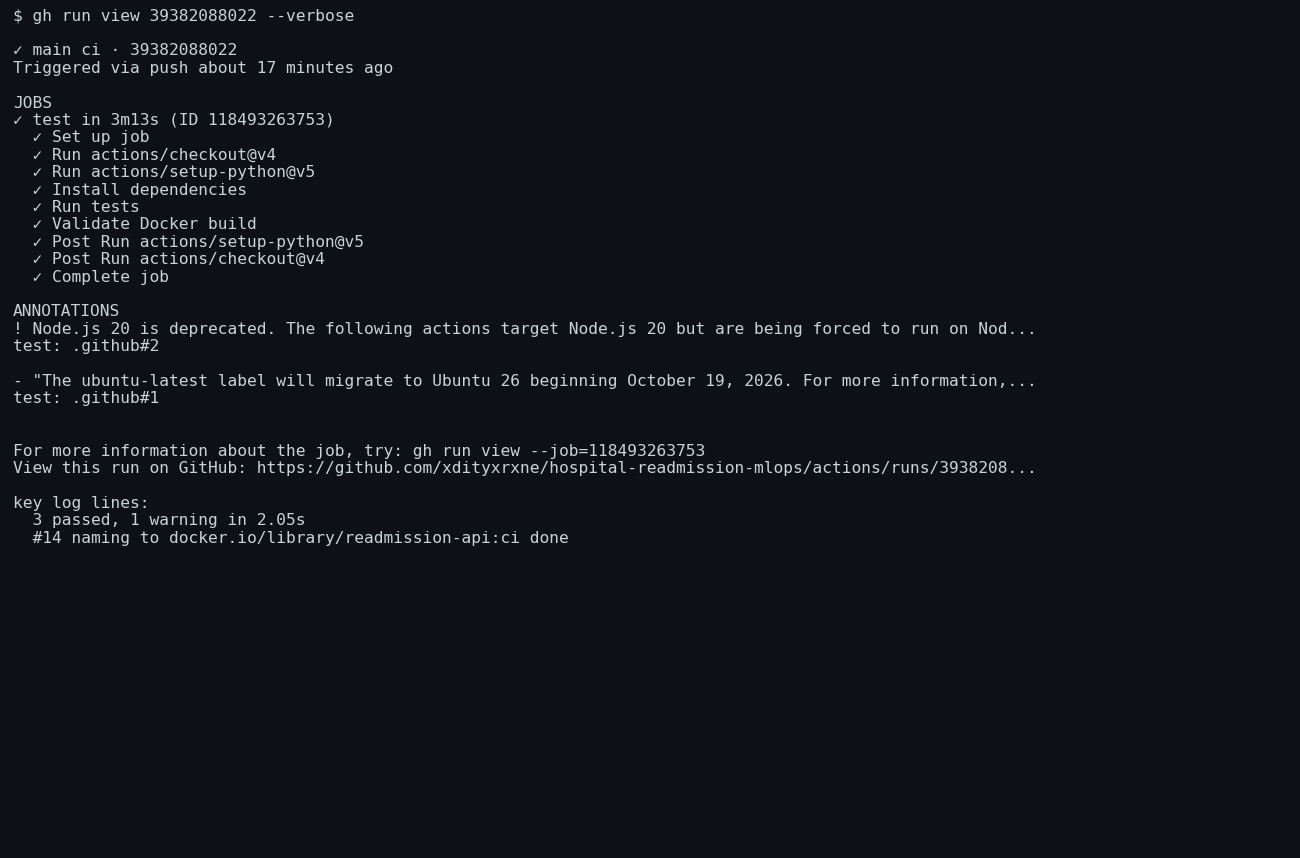


--- 4.3 component validation ---
  [PASS] workflow file exists
  [PASS] triggers on push
  [PASS] triggers on pull_request
  [PASS] checks out the repo
  [PASS] sets up python
  [PASS] installs requirements.txt
  [PASS] runs pytest
  [PASS] validates the docker build
  [PASS] tests/ directory present
  [PASS] pytest exits 0 locally
  [PASS] hosted GitHub Actions run succeeded
11/11 checks passed


2001

In [3]:
# TODO 4.3.1: print your .github/workflows/ci.yml.
# TODO 4.3.2: run the test suite here (subprocess pytest) AND include a green-run screenshot.

# ===== SOLUTION START =====
import json
import shutil
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt

import config as cfg

ART = cfg.ARTIFACT_DIR
EVIDENCE = ART / 'evidence'
EVIDENCE.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# 4.3.1  the workflow definition
# -----------------------------------------------------------------------------
workflow = Path('.github/workflows/ci.yml')
wf_text = workflow.read_text(encoding='utf-8')
print(f'--- {workflow} ---')
print(wf_text)

# -----------------------------------------------------------------------------
# 4.3.2 (a)  run the test suite here - the same command CI runs
# -----------------------------------------------------------------------------
print('--- 4.3.2 pytest (local execution of the CI step) ---')
proc = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests/'],
                      capture_output=True, text=True)
pytest_output = (proc.stdout or '') + (proc.stderr or '')
print(pytest_output.strip() or '(no output)')
print('exit code:', proc.returncode)
(EVIDENCE / 'pytest_output.txt').write_text(
    f'$ pytest -q tests/\n\n{pytest_output}\nexit code: {proc.returncode}\n', encoding='utf-8')

# -----------------------------------------------------------------------------
# 4.3.2 (b)  the hosted GitHub Actions run of the same workflow
# -----------------------------------------------------------------------------
gh = shutil.which('gh')
ci_run = {}
# plain (uncoloured) gh output, even if the notebook environment forces colour
import os
gh_env = {k: v for k, v in os.environ.items() if k not in ('FORCE_COLOR', 'CLICOLOR_FORCE', 'GH_FORCE_TTY')}
gh_env['NO_COLOR'] = '1'
if gh:
    listing = subprocess.run(
        [gh, 'run', 'list', '--workflow', 'ci.yml', '--limit', '5', '--json',
         'databaseId,status,conclusion,headSha,displayTitle,createdAt,url,event'],
        capture_output=True, text=True, env=gh_env)
    runs = json.loads(listing.stdout) if listing.returncode == 0 and listing.stdout.strip() else []
    green = [r for r in runs if r.get('conclusion') == 'success']
    if green:
        ci_run = green[0]
        view = subprocess.run([gh, 'run', 'view', str(ci_run['databaseId']), '--verbose'],
                              capture_output=True, text=True, encoding='utf-8', errors='replace',
                              env=gh_env)
        log = subprocess.run([gh, 'run', 'view', str(ci_run['databaseId']), '--log'],
                             capture_output=True, text=True, encoding='utf-8', errors='replace',
                             env=gh_env)
        key_lines = [ln.split('Z ', 1)[-1] for ln in log.stdout.splitlines()
                     if ' passed' in ln or 'naming to docker.io' in ln or 'Successfully installed' in ln]
        ci_run['key_log_lines'] = [ln[:160] for ln in key_lines]
        ci_run['view'] = (view.stdout.strip() + '\n\nkey log lines:\n'
                          + '\n'.join('  ' + ln[:110] for ln in key_lines if 'Successfully installed' not in ln))
        print('\n--- GitHub Actions: latest successful run of ci.yml ---')
        print(ci_run['view'])
        print('\nrun URL:', ci_run['url'])
        (EVIDENCE / 'github_actions_run.txt').write_text(ci_run['view'], encoding='utf-8')

        # render the gh CLI output as a terminal-style image for the report
        shown = [ln if len(ln) <= 105 else ln[:102] + '...'
                 for ln in (f"$ gh run view {ci_run['databaseId']} --verbose\n\n" + ci_run['view']).splitlines()]
        fig = plt.figure(figsize=(10, 0.2 * len(shown) + 0.4))
        fig.patch.set_facecolor('#0d1117')
        fig.text(0.01, 0.99, '\n'.join(shown), family='monospace', fontsize=9,
                 color='#c9d1d9', va='top')
        fig.savefig(EVIDENCE / 'github_actions_run.png', dpi=130, facecolor=fig.get_facecolor())
        plt.close(fig)
        from IPython.display import Image, display as show
        show(Image(filename=str(EVIDENCE / 'github_actions_run.png'), width=900))
    else:
        print('\nno successful GitHub Actions run found for this repository yet:',
              [(r.get('status'), r.get('conclusion')) for r in runs])
else:
    print('\ngh CLI not available - the hosted run cannot be queried from here.')

# -----------------------------------------------------------------------------
# Independent validation of the CI component (requirement 8)
# -----------------------------------------------------------------------------
lower = wf_text.lower()
checks = [
    ('workflow file exists', workflow.exists()),
    ('triggers on push', 'push' in lower),
    ('triggers on pull_request', 'pull_request' in lower),
    ('checks out the repo', 'actions/checkout' in lower),
    ('sets up python', 'actions/setup-python' in lower),
    ('installs requirements.txt', 'requirements.txt' in lower),
    ('runs pytest', 'pytest' in lower),
    ('validates the docker build', 'docker build' in lower),
    ('tests/ directory present', Path('tests').is_dir()),
    ('pytest exits 0 locally', proc.returncode == 0),
    ('hosted GitHub Actions run succeeded', ci_run.get('conclusion') == 'success'),
]
print('\n--- 4.3 component validation ---')
for name, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
print(f"{sum(ok for _, ok in checks)}/{len(checks)} checks passed")

(EVIDENCE / 'ci_evidence.json').write_text(json.dumps({
    'workflow': wf_text,
    'pytest_exit_code': proc.returncode,
    'pytest_output': pytest_output,
    'github_actions_run': {k: v for k, v in ci_run.items() if k != 'view'},
    'checks': {name: bool(ok) for name, ok in checks},
}, indent=2), encoding='utf-8')
# ===== SOLUTION END =====

## Stage 4.4 — Monitoring & Drift Detection <font color="red">[4 marks]</font>

Implement `run_monitoring()` in `src/monitoring.py`.

- **4.4.1 — Feature drift (Evidently, reference vs current) [2]** — run an Evidently `DataDriftPreset` (reference vs current batch); summarise + visualise.
- **4.4.2 — Prediction drift (PSI on scores) + interpretation [2]** — compute PSI on model scores and interpret (prediction drift can exceed feature-level drift).

wrote current_batch.csv (5000 rows) with injected drift


feature drift : 6/37 columns (share=0.1622, dataset_drift=False)
prediction PSI: 0.2484 (significant shift (>0.20)) mean 0.4698 -> 0.5311

--- drift_summary.json (per-column detail shown as a table below) ---
{
  "generated_at": "2026-10-20T07:01:11.583658+00:00",
  "n_reference_rows": 5000,
  "n_current_rows": 5000,
  "number_of_columns": 37,
  "number_of_drifted_columns": 6,
  "share_drifted": 0.1622,
  "dataset_drift": false,
  "drifted_columns": [
    "age",
    "time_in_hospital",
    "num_medications",
    "number_inpatient",
    "service_utilization",
    "diag_1"
  ],
  "drift_method": "evidently 0.7 DataDriftPreset",
  "prediction_psi": 0.2484,
  "psi_interpretation": "significant shift (>0.20)",
  "reference_score_mean": 0.4698,
  "current_score_mean": 0.5311,
  "report_html": "drift_report.html"
}

Evidently per-column drift tests (method chosen by Evidently per column type/size):


,column,method,score,threshold,drift_detected
0,number_inpatient,Wasserstein distance (normed),0.813770,0.10,True
1,time_in_hospital,Wasserstein distance (normed),0.622972,0.10,True
2,age,Wasserstein distance (normed),0.619675,0.10,True
3,num_medications,Wasserstein distance (normed),0.441788,0.10,True
4,service_utilization,Wasserstein distance (normed),0.354057,0.10,True
5,diag_1,Jensen-Shannon distance,0.117540,0.10,True
6,A1Cresult,chi-square p_value,0.233336,0.05,False
7,max_glu_serum,chi-square p_value,0.145962,0.05,False
8,medical_specialty,Jensen-Shannon distance,0.032175,0.10,False
9,admission_source_id,Jensen-Shannon distance,0.030196,0.10,False


Evidently report -> evidently_drift_report.png


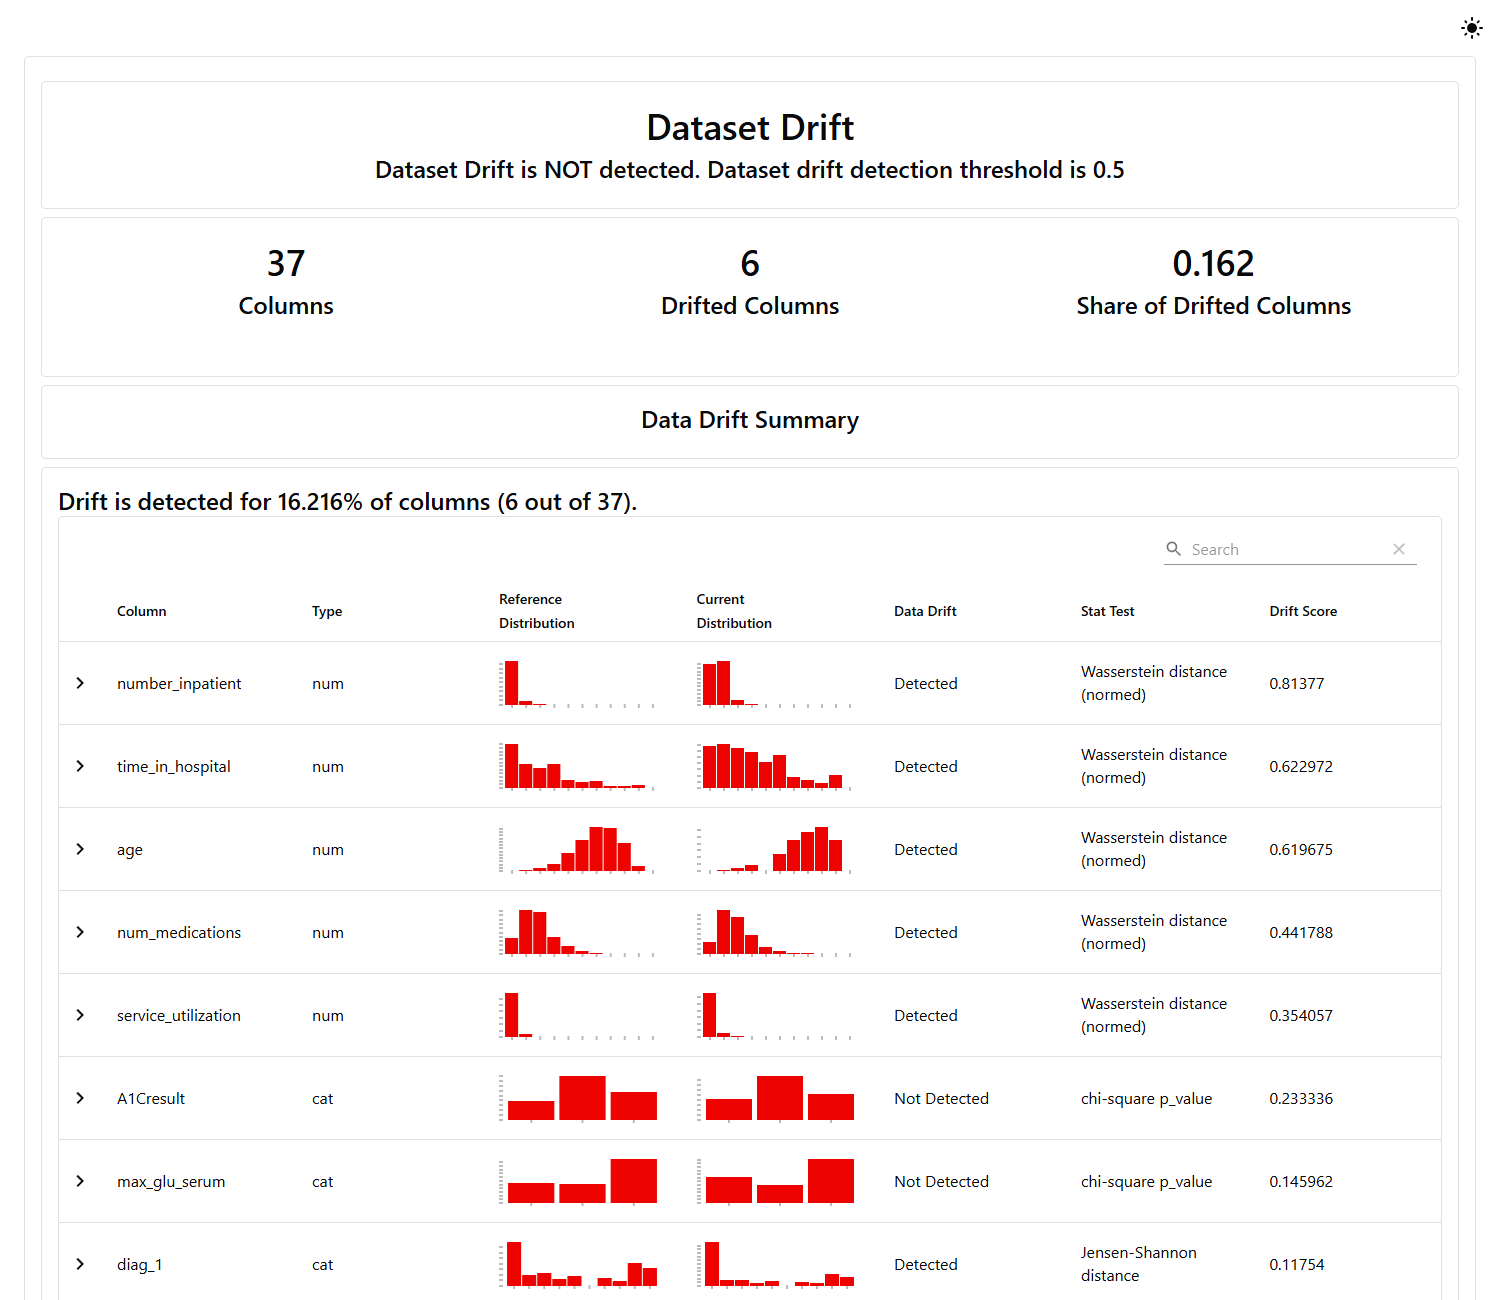

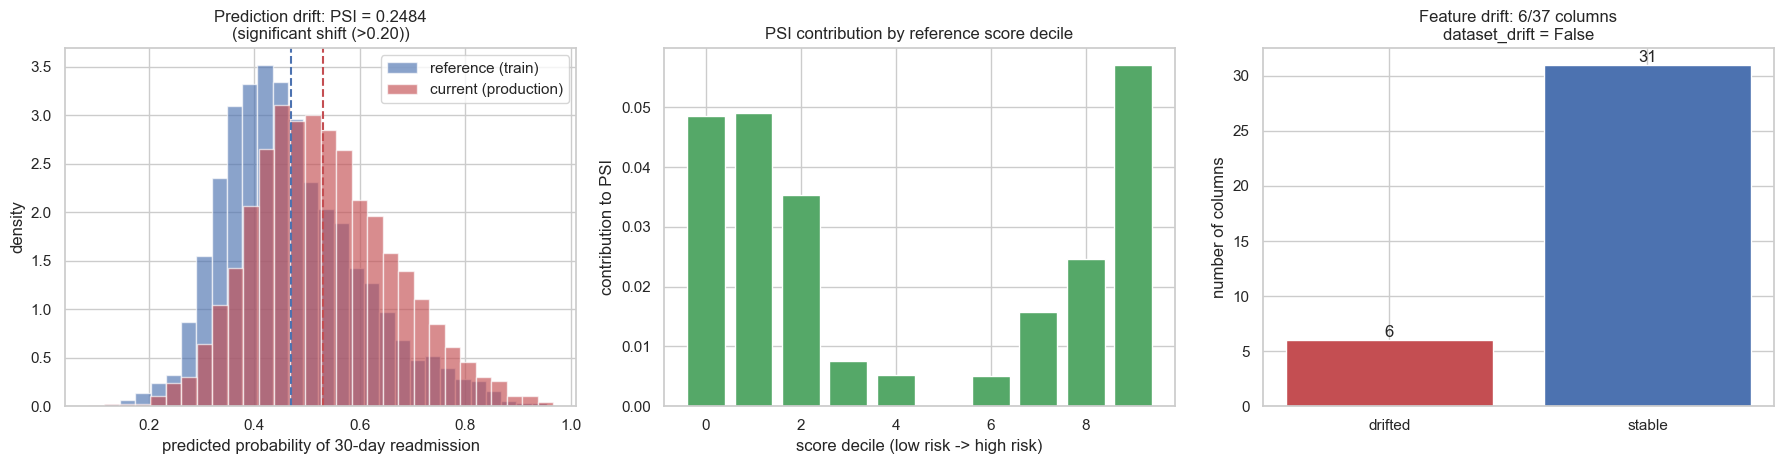

drifted columns: age, time_in_hospital, num_medications, number_inpatient, service_utilization, diag_1

--- 4.4 interpretation ---
Feature drift. Evidently's DataDriftPreset flagged 6 of 37 columns as drifted (share 0.162):
age, time_in_hospital, num_medications, number_inpatient, service_utilization, diag_1. These
are exactly the shifts injected by src/generate_current_batch.py (age +10, longer stays,
more medications and prior inpatient visits - hence service_utilization - and a heavier
Circulatory diag_1 mix); every other column stays below its distance threshold. The dataset-
level verdict is dataset_drift=False, because that flag needs at least half of the columns
to move.

Prediction drift. PSI on the model scores is 0.2484 -> significant shift (>0.20). Mean
predicted risk moved from 0.4698 to 0.5311.

Why prediction drift is the stronger signal. Only a handful of inputs shifted, but they are
the ones the model leans on (prior inpatient visits, utilisation, length of stay,
medica

8903

In [4]:
# TODO 4.4.1: generate a current batch (src.generate_current_batch); run Evidently feature drift.
# TODO 4.4.2: compute prediction PSI on model scores; summarise, plot and interpret.

# ===== SOLUTION START =====
import json
import textwrap
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

import config as cfg
from src import data_prep as dp
from src.monitoring import psi, run_monitoring

ART = cfg.ARTIFACT_DIR
EVIDENCE = ART / 'evidence'
EVIDENCE.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# 4.4.1  simulate the post-deployment batch with the PROVIDED generator, then run
#        the drift pipeline (Evidently DataDriftPreset + prediction PSI)
# -----------------------------------------------------------------------------
from src.generate_current_batch import main as generate_current_batch

generate_current_batch()          # older age skew, longer stays, more meds/inpatient, more Circulatory
batch_source = 'src.generate_current_batch'

summary = run_monitoring()

print('\n--- drift_summary.json (per-column detail shown as a table below) ---')
print(json.dumps({k: v for k, v in summary.items() if k != 'column_drift'}, indent=2))

col_table = (pd.DataFrame(summary['column_drift'])
             .sort_values(['drift_detected', 'score'], ascending=[False, False]))
print('\nEvidently per-column drift tests (method chosen by Evidently per column type/size):')
display(col_table.head(12).reset_index(drop=True))

# Screenshot of the Evidently HTML report itself (the raw HTML is not submitted)
from IPython.display import Image, display as show
report_png = browser_screenshot((ART / 'drift_report.html').resolve().as_uri(),
                                EVIDENCE / 'evidently_drift_report.png', height=1300)
if report_png:
    print('Evidently report ->', report_png.name)
    show(Image(filename=str(report_png), width=1100))

# -----------------------------------------------------------------------------
# 4.4.2  score distributions behind the prediction PSI
# -----------------------------------------------------------------------------
reference = pd.read_csv(ART / 'reference_sample.csv')
current = pd.read_csv(ART / 'current_batch.csv')
shared = [c for c in reference.columns if c in current.columns]

model = joblib.load(ART / 'best_model.pkl')
ref_scores = model.predict_proba(reference[shared])[:, 1]
cur_scores = model.predict_proba(current[shared])[:, 1]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

ax[0].hist(ref_scores, bins=30, alpha=0.65, label='reference (train)',
           color='#4C72B0', density=True)
ax[0].hist(cur_scores, bins=30, alpha=0.65, label='current (production)',
           color='#C44E52', density=True)
ax[0].axvline(ref_scores.mean(), color='#4C72B0', ls='--', lw=1.5)
ax[0].axvline(cur_scores.mean(), color='#C44E52', ls='--', lw=1.5)
ax[0].set_title(f"Prediction drift: PSI = {summary['prediction_psi']:.4f}\n"
                f"({summary['psi_interpretation']})")
ax[0].set_xlabel('predicted probability of 30-day readmission')
ax[0].set_ylabel('density')
ax[0].legend()

# PSI contribution per decile of the reference score distribution
edges = np.unique(np.quantile(ref_scores, np.linspace(0, 1, 11)))
e_pct = np.histogram(ref_scores, bins=edges)[0] / len(ref_scores)
a_pct = np.histogram(cur_scores, bins=edges)[0] / len(cur_scores)
eps = 1e-6
e_pct, a_pct = np.clip(e_pct, eps, None), np.clip(a_pct, eps, None)
contrib = (a_pct - e_pct) * np.log(a_pct / e_pct)

ax[1].bar(range(len(contrib)), contrib, color='#55A868')
ax[1].set_title('PSI contribution by reference score decile')
ax[1].set_xlabel('score decile (low risk -> high risk)')
ax[1].set_ylabel('contribution to PSI')

n_drifted = summary['number_of_drifted_columns']
n_stable = summary['number_of_columns'] - n_drifted
ax[2].bar(['drifted', 'stable'], [n_drifted, n_stable],
          color=['#C44E52', '#4C72B0'])
ax[2].set_title(f"Feature drift: {n_drifted}/{summary['number_of_columns']} columns\n"
                f"dataset_drift = {summary['dataset_drift']}")
ax[2].set_ylabel('number of columns')
for i, v in enumerate([n_drifted, n_stable]):
    ax[2].text(i, v, str(v), ha='center', va='bottom')

plt.tight_layout()
plt.savefig(EVIDENCE / 'drift_plots.png', dpi=120, bbox_inches='tight')
plt.show()

if summary['drifted_columns']:
    print('drifted columns:', ', '.join(summary['drifted_columns']))

# -----------------------------------------------------------------------------
# 4.4.2  interpretation
# -----------------------------------------------------------------------------
drifted = summary['drifted_columns']
fired_psi = summary['prediction_psi'] > 0.2
paragraphs = [
    f"Feature drift. Evidently's DataDriftPreset flagged {n_drifted} of "
    f"{summary['number_of_columns']} columns as drifted (share {summary['share_drifted']:.3f}): "
    f"{', '.join(drifted) if drifted else 'none'}. These are exactly the shifts injected by "
    "src/generate_current_batch.py (age +10, longer stays, more medications and prior inpatient "
    "visits - hence service_utilization - and a heavier Circulatory diag_1 mix); every other "
    "column stays below its distance threshold. The dataset-level verdict is "
    f"dataset_drift={summary['dataset_drift']}, because that flag needs at least half of the "
    "columns to move.",

    f"Prediction drift. PSI on the model scores is {summary['prediction_psi']:.4f} -> "
    f"{summary['psi_interpretation']}. Mean predicted risk moved from "
    f"{summary['reference_score_mean']:.4f} to {summary['current_score_mean']:.4f}.",

    ("Why prediction drift is the stronger signal. Only a handful of inputs shifted, but they are "
     "the ones the model leans on (prior inpatient visits, utilisation, length of stay, "
     "medications, age), and they all push risk in the same direction. Per-column drift dilutes "
     "that across the full schema; prediction drift aggregates the correlated moves into one "
     "distribution - so the output-side signal crosses its threshold while the dataset-level "
     "feature verdict stays False. Monitoring the score distribution is therefore not optional.")
    if fired_psi else
    ("Prediction drift is below the 0.2 trigger, so although individual features moved, the "
     "score distribution the care team acts on is still within tolerance."),

    "Operational reading. Scores have moved enough to change who crosses the 0.5 threshold, so "
    "alert volume and the precision the care team experiences will differ from validation. "
    "Ground-truth labels arrive 30 days later, so PSI is the earliest trustworthy signal and it "
    "is wired into the Stage 4.5 trigger.",
]
print('\n--- 4.4 interpretation ---')
for para in paragraphs:
    print(textwrap.fill(para, width=92))
    print()

# -----------------------------------------------------------------------------
# Independent validation of the drift component (requirement 8)
# -----------------------------------------------------------------------------
checks = [
    ('current_batch.csv generated', (ART / 'current_batch.csv').exists()),
    ('drift_report.html written', (ART / 'drift_report.html').exists()),
    ('Evidently (not the SciPy fallback) produced the verdict',
     summary['drift_method'].startswith('evidently')),
    ('drift_summary.json written', (ART / 'drift_summary.json').exists()),
    ('feature drift counted', summary['number_of_columns'] > 0),
    ('prediction PSI computed', summary['prediction_psi'] is not None),
    ('PSI is non-negative', summary['prediction_psi'] >= 0),
    ('drift plots saved', (EVIDENCE / 'drift_plots.png').exists()),
]
print('--- 4.4 component validation ---')
for name, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
print(f"{sum(ok for _, ok in checks)}/{len(checks)} checks passed")

(EVIDENCE / 'drift_evidence.json').write_text(json.dumps({
    'summary': {k: v for k, v in summary.items() if k != 'column_drift'},
    'column_drift': summary['column_drift'],
    'batch_source': batch_source,
    'checks': {name: bool(ok) for name, ok in checks},
    'interpretation': paragraphs,
}, indent=2))
# ===== SOLUTION END =====


## Stage 4.5 — Retraining Workflow <font color="red">[3 marks]</font>

Implement the trigger + workflow in `src/retrain.py`.

- **4.5.1 — Multi-signal retraining trigger defined [1]** — prediction PSI > 0.2 OR drifted share > 0.3 OR dataset drift.
- **4.5.2 — Retraining workflow runs + re-registers + decision record [2]** — on a trigger, retrain + register a new version and record the decision (`retraining_decision.json`).

In [5]:
# TODO 4.5.1: define the multi-signal trigger.
# TODO 4.5.2: on a trigger, retrain + register a new version; show the decision record.

# ===== SOLUTION START =====
import json
import textwrap

import pandas as pd

import config as cfg
from src.retrain import (DRIFT_SHARE_THRESHOLD, PSI_THRESHOLD, decide,
                         run_retraining_workflow)

ART = cfg.ARTIFACT_DIR
EVIDENCE = ART / 'evidence'
EVIDENCE.mkdir(parents=True, exist_ok=True)

summary = json.loads((ART / 'drift_summary.json').read_text())

# -----------------------------------------------------------------------------
# 4.5.1  the multi-signal trigger: OR over three independent drift signals
# -----------------------------------------------------------------------------
signals = pd.DataFrame([
    {'signal': 'prediction PSI',
     'observed': summary['prediction_psi'],
     'threshold': f'> {PSI_THRESHOLD}',
     'fired': summary['prediction_psi'] > PSI_THRESHOLD},
    {'signal': 'share of drifted features',
     'observed': summary['share_drifted'],
     'threshold': f'> {DRIFT_SHARE_THRESHOLD}',
     'fired': summary['share_drifted'] > DRIFT_SHARE_THRESHOLD},
    {'signal': 'Evidently dataset_drift',
     'observed': summary['dataset_drift'],
     'threshold': 'is True',
     'fired': bool(summary['dataset_drift'])},
])
print('--- 4.5.1 retraining trigger (fires if ANY signal is True) ---')
print(signals.to_string(index=False))

reasons = decide(summary)
print(f"\ndecide() -> {len(reasons)} reason(s); retrain = {bool(reasons)}")
for reason in reasons:
    print('  -', reason)

# -----------------------------------------------------------------------------
# 4.5.2  run the workflow: retrain -> re-register -> record the decision
# -----------------------------------------------------------------------------
print('\n--- 4.5.2 retraining workflow ---')
decision = run_retraining_workflow()

print('\n--- retraining_decision.json ---')
print(json.dumps(decision, indent=2))

note = (
    "Why an OR over three signals. Each signal fails in a different way, so no one "
    "of them is sufficient on its own. Prediction PSI catches correlated input shifts "
    "that collapse into the score distribution but leave most columns individually "
    "unremarkable - which is precisely this batch. The drifted-share signal catches "
    "broad schema or population change that might leave scores stable, for example an "
    "upstream coding change. Evidently's dataset_drift flag is the conservative "
    "dataset-level verdict. Requiring agreement would make the trigger too slow to be "
    "useful; an OR keeps it sensitive, and the decision record makes every firing "
    "auditable."
)
print('\n--- 4.5 interpretation ---')
print(textwrap.fill(note, width=92))

# -----------------------------------------------------------------------------
# Independent validation of the retraining component (requirement 8)
# -----------------------------------------------------------------------------
# decide() is pure, so its logic is testable without retraining anything.
unit_cases = [
    ({'prediction_psi': 0.0, 'share_drifted': 0.0, 'dataset_drift': False}, 0),
    ({'prediction_psi': 0.5, 'share_drifted': 0.0, 'dataset_drift': False}, 1),
    ({'prediction_psi': 0.0, 'share_drifted': 0.9, 'dataset_drift': False}, 1),
    ({'prediction_psi': 0.0, 'share_drifted': 0.0, 'dataset_drift': True}, 1),
    ({'prediction_psi': 0.5, 'share_drifted': 0.9, 'dataset_drift': True}, 3),
]
unit_ok = all(len(decide(case)) == expected for case, expected in unit_cases)

checks = [
    ('decide() returns the expected reason count on 5 synthetic cases', unit_ok),
    ('trigger fired on the live summary', bool(reasons)),
    ('decision record written',
     (ART / 'retraining_decision.json').exists()),
    ('decision names the triggered signals', bool(decision.get('reasons'))),
    ('decision records the thresholds used', 'thresholds' in decision),
    ('retrain completed and re-registered',
     decision.get('action') == 'retrained_and_registered'),
    ('new registry version recorded',
     decision.get('new_registered_version') is not None),
]
print('\n--- 4.5 component validation ---')
for name, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
print(f"{sum(ok for _, ok in checks)}/{len(checks)} checks passed")

(EVIDENCE / 'retraining_evidence.json').write_text(json.dumps({
    'signals': signals.to_dict(orient='records'),
    'reasons': reasons,
    'decision': decision,
    'checks': {name: bool(ok) for name, ok in checks},
    'rationale': note,
}, indent=2))
# ===== SOLUTION END =====

--- 4.5.1 retraining trigger (fires if ANY signal is True) ---
                   signal observed threshold  fired
           prediction PSI   0.2484     > 0.2   True
share of drifted features   0.1622     > 0.3  False
  Evidently dataset_drift    False   is True  False

decide() -> 1 reason(s); retrain = True
  - prediction drift: PSI 0.2484 > 0.2 (significant shift (>0.20))

--- 4.5.2 retraining workflow ---
retraining triggered:
  - prediction drift: PSI 0.2484 > 0.2 (significant shift (>0.20))


train (44782, 37) | val (11196, 37) | test (13995, 37)
scale_pos_weight = 40,764/4,018 = 10.1453


logged logistic_regression  val_roc_auc=0.6528 val_pr_auc=0.1715 recall=0.5428


Registered model 'readmission_classifier' already exists. Creating a new version of this model...
2026/10/20 12:31:54 WARNING mlflow.tracking._model_registry.fluent: Run with id ca97d70766734c4383f8ef7a187860d6 has no artifacts at artifact path 'model', registering model based on models:/m-51645ab927db4fbb86f1a03822d37c20 instead


logged xgboost              val_roc_auc=0.6480 val_pr_auc=0.1754 recall=0.4502

best by val ROC-AUC: logistic_regression (0.6528)
registered readmission_classifier v2 and promoted to 'production'


Created version '2' of model 'readmission_classifier'.


test metrics: {'roc_auc': 0.6454, 'pr_auc': 0.1666, 'f1': 0.2186, 'recall': 0.5235, 'precision': 0.1382, 'accuracy': 0.6645}
artefacts saved to C:\Users\rane5\OneDrive\Desktop\Capstone Project\Capstone Project\MLOps 1 - Starter\artifacts

decision: retrained_and_registered -> artifacts/retraining_decision.json

--- retraining_decision.json ---
{
  "evaluated_at": "2026-10-20T07:01:22.211138+00:00",
  "thresholds": {
    "psi_threshold": 0.2,
    "drift_share_threshold": 0.3
  },
  "signals": {
    "prediction_psi": 0.2484,
    "share_drifted": 0.1622,
    "number_of_drifted_columns": 6,
    "number_of_columns": 37,
    "dataset_drift": false
  },
  "retrain_triggered": true,
  "reasons": [
    "prediction drift: PSI 0.2484 > 0.2 (significant shift (>0.20))"
  ],
  "action": "retrained_and_registered",
  "new_model": "logistic_regression",
  "new_metrics": {
    "roc_auc": 0.6454,
    "pr_auc": 0.1666,
    "f1": 0.2186,
    "recall": 0.5235,
    "precision": 0.1382,
    "accuracy": 0.66

2341

## Stage 4.6 — Logging & Governance <font color="red">[4 marks]</font>

- **4.6.1 — Prediction logging [2]** — show the `predictions.log` tail (proof predictions are logged).
- **4.6.2 — Model governance (registry history + alias + pinned deps) [2]** — show the MLflow registry version history + the `production` alias + pinned `requirements.txt`.

--- C:\Users\rane5\OneDrive\Desktop\Capstone Project\Capstone Project\MLOps 1 - Starter\artifacts\predictions.log ---
3 prediction(s) logged; last 3:

{
  "ts": "2026-10-20T06:54:40.076326+00:00",
  "endpoint": "/predict",
  "n_features_sent": 37,
  "n_missing_fields": 1,
  "unknown_fields": [],
  "readmission_probability": 0.457436,
  "readmitted_30d": 0,
  "threshold": 0.5
}
{
  "ts": "2026-10-20T06:54:40.102888+00:00",
  "endpoint": "/predict",
  "n_features_sent": 6,
  "n_missing_fields": 31,
  "unknown_fields": [],
  "readmission_probability": 0.412236,
  "readmitted_30d": 0,
  "threshold": 0.5
}
{
  "ts": "2026-10-20T07:00:51.954513+00:00",
  "endpoint": "/predict",
  "n_features_sent": 37,
  "n_missing_fields": 1,
  "unknown_fields": [],
  "readmission_probability": 0.457436,
  "readmitted_30d": 0,
  "threshold": 0.5
}

--- logged predictions as a frame ---
                              ts endpoint  n_features_sent  n_missing_fields unknown_fields  readmission_probability  readm

registered model: readmission_classifier
tracking URI    : sqlite:///mlflow.db

 version   run_id status    aliases val_roc_auc                 created
       1 f8be9b08  READY                 0.6528 2026-10-20 06:54:05.541
       2 ca97d707  READY production      0.6528 2026-10-20 07:01:54.186

production alias -> version 2 (run ca97d707)
load with: mlflow.sklearn.load_model('models:/readmission_classifier@production')



MLflow registry after retraining -> mlflow_registry_after_retrain.png


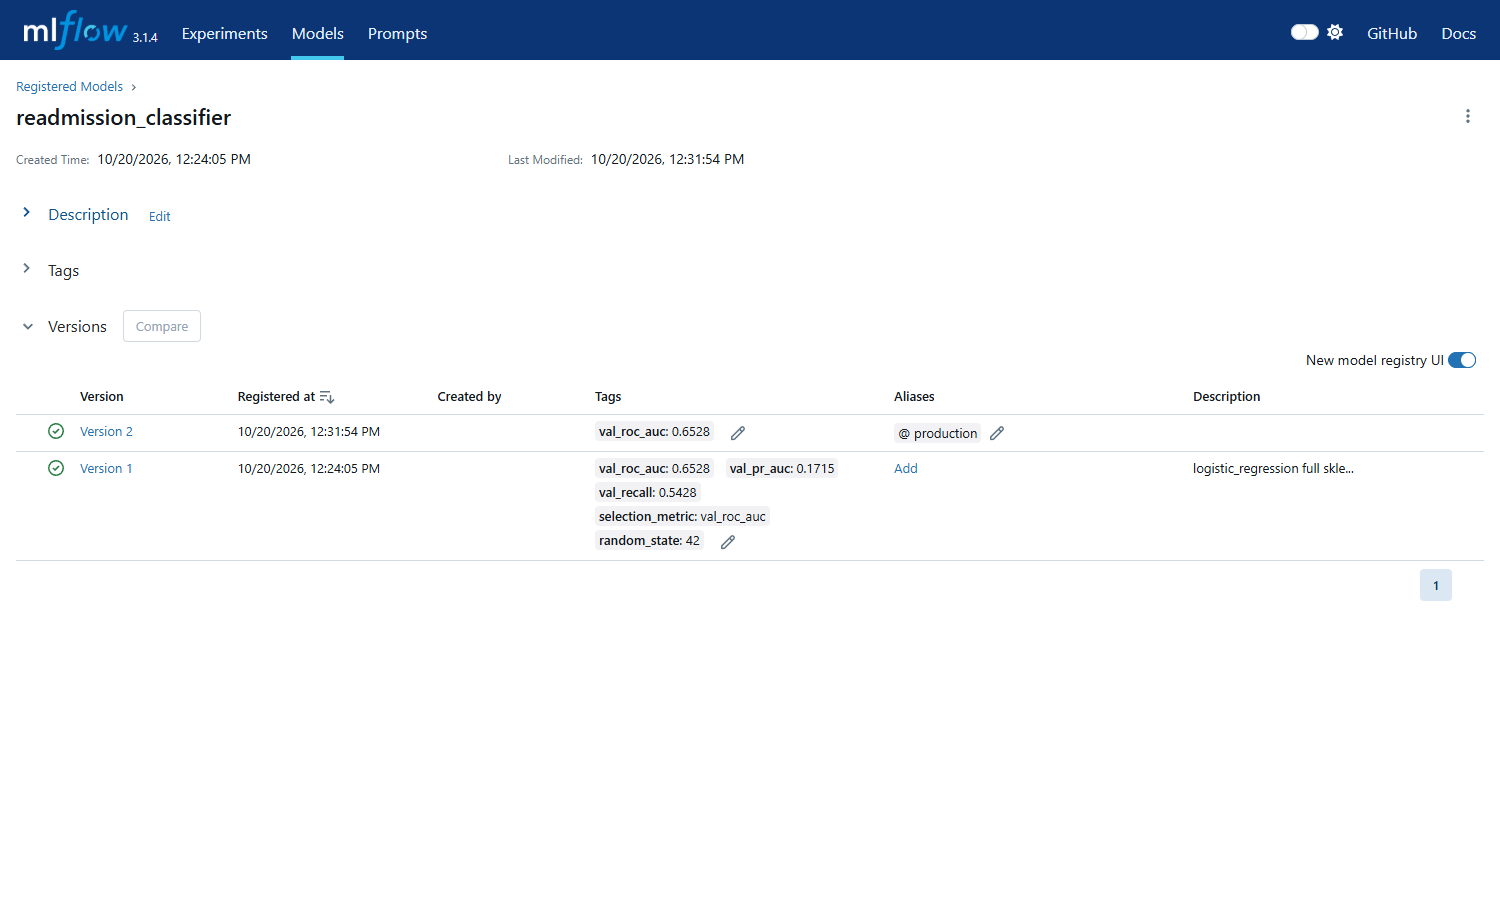


--- pinned dependencies (requirements.txt) ---
# Hospital Readmission MLOps — pinned deps (Python 3.11+)
pandas==2.3.3
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
mlflow==3.1.4
fastapi==0.128.8
uvicorn==0.39.0
evidently==0.7.20
imbalanced-learn==0.12.4
joblib==1.5.3
matplotlib==3.9.4
seaborn==0.13.2
pytest==8.4.2
requests==2.32.5
pyarrow==20.0.0
# transitive pin: mlflow 3.1.4 imports FallbackAsyncAdaptedQueuePool, removed in SQLAlchemy 2.1
sqlalchemy==2.0.55

16 pinned with ==, 0 unpinned

--- 4.6 component validation ---
  [PASS] predictions.log exists
  [PASS] at least one prediction logged
  [PASS] log lines are valid JSON
  [PASS] log records probability + label + threshold
  [PASS] log is timestamped
  [PASS] registry has at least one version
  [PASS] more than one version (retrain bumped it)
  [PASS] production alias resolves
  [PASS] requirements.txt present
  [PASS] dependencies pinned with ==
10/10 checks passed

--- evidence manifest (requirement 9) ---
  [OK] evidence/a

In [6]:
# TODO 4.6.1: show the predictions.log tail.
# TODO 4.6.2: show the MLflow registry version history + production alias (governance).

# ===== SOLUTION START =====
import json
from pathlib import Path

import pandas as pd

import config as cfg

ART = cfg.ARTIFACT_DIR
EVIDENCE = ART / 'evidence'
EVIDENCE.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# 4.6.1  prediction logging — every /predict call appends one JSON line
# -----------------------------------------------------------------------------
log_path = ART / 'predictions.log'
print(f'--- {log_path} ---')

log_lines = log_path.read_text().splitlines() if log_path.exists() else []
print(f'{len(log_lines)} prediction(s) logged; last {min(5, len(log_lines))}:\n')
for line in log_lines[-5:]:
    print(json.dumps(json.loads(line), indent=2))

if log_lines:
    logged = pd.DataFrame([json.loads(l) for l in log_lines])
    print('\n--- logged predictions as a frame ---')
    print(logged.tail(5).to_string(index=False))
    print(f"\nmean logged probability : {logged['readmission_probability'].mean():.4f}")
    print(f"flagged readmitted_30d=1: {int(logged['readmitted_30d'].sum())}"
          f" of {len(logged)}")

# -----------------------------------------------------------------------------
# 4.6.2  model governance — registry history, production alias, pinned deps
# -----------------------------------------------------------------------------
print('\n--- 4.6.2 MLflow model registry ---')
registry_rows, alias_version = [], None
try:
    import mlflow
    from mlflow.tracking import MlflowClient

    mlflow.set_tracking_uri(cfg.MLFLOW_TRACKING_URI)
    client = MlflowClient()

    # search_model_versions does not populate aliases -> re-read each version
    for found in client.search_model_versions(f"name='{cfg.REGISTERED_MODEL}'"):
        mv = client.get_model_version(cfg.REGISTERED_MODEL, found.version)
        registry_rows.append({
            'version': int(mv.version),
            'run_id': (mv.run_id or '')[:8],
            'status': mv.status,
            'aliases': ', '.join(mv.aliases) if getattr(mv, 'aliases', None) else '',
            'val_roc_auc': (mv.tags or {}).get('val_roc_auc', ''),
            'created': pd.to_datetime(mv.creation_timestamp, unit='ms'),
        })

    history = (pd.DataFrame(registry_rows).sort_values('version')
               if registry_rows else pd.DataFrame())
    print(f"registered model: {cfg.REGISTERED_MODEL}")
    print(f"tracking URI    : {cfg.MLFLOW_TRACKING_URI}\n")
    print(history.to_string(index=False) if not history.empty
          else '(no versions found)')

    try:
        prod = client.get_model_version_by_alias(cfg.REGISTERED_MODEL, 'production')
        alias_version = int(prod.version)
        print(f"\nproduction alias -> version {alias_version} "
              f"(run {(prod.run_id or '')[:8]})")
        print(f"load with: mlflow.sklearn.load_model("
              f"'models:/{cfg.REGISTERED_MODEL}@production')")
    except Exception as exc:
        print('\ncould not resolve the production alias:', exc)
except Exception as exc:
    print('MLflow registry unavailable:', f'{type(exc).__name__}: {exc}')

# -----------------------------------------------------------------------------
# Pinned dependencies — the reproducibility half of governance
# -----------------------------------------------------------------------------
# MLflow UI screenshot of the registry after the retrain (v1 + v2, alias on v2)
import socket, subprocess, sys, os, time
from IPython.display import Image, display as show
with socket.socket() as sock:
    sock.bind(('127.0.0.1', 0))
    ui_port = sock.getsockname()[1]
ui = subprocess.Popen([sys.executable, '-m', 'mlflow', 'ui', '--backend-store-uri',
                       cfg.MLFLOW_TRACKING_URI, '--port', str(ui_port)],
                      stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
try:
    import requests
    for _ in range(90):
        try:
            if requests.get(f'http://127.0.0.1:{ui_port}/health', timeout=1).ok:
                break
        except Exception:
            time.sleep(1)

    def close_popup(page):
        close = page.locator('button[aria-label="Close"]')
        if close.count():
            close.first.click()
            page.wait_for_timeout(500)

    reg_png = browser_screenshot(f'http://127.0.0.1:{ui_port}/#/models/{cfg.REGISTERED_MODEL}',
                                 EVIDENCE / 'mlflow_registry_after_retrain.png',
                                 prepare=close_popup)
finally:
    if os.name == 'nt':
        subprocess.run(['taskkill', '/F', '/T', '/PID', str(ui.pid)], capture_output=True)
    else:
        ui.terminate()
if reg_png:
    print('\nMLflow registry after retraining ->', reg_png.name)
    show(Image(filename=str(reg_png), width=1100))

req = Path('requirements.txt')
print('\n--- pinned dependencies (requirements.txt) ---')
pinned, unpinned = [], []
if req.exists():
    for line in req.read_text(encoding='utf-8').splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        (pinned if '==' in line else unpinned).append(line)
    print(req.read_text(encoding='utf-8'))
    print(f'{len(pinned)} pinned with ==, {len(unpinned)} unpinned')
    if unpinned:
        print('unpinned:', ', '.join(unpinned))
else:
    print('requirements.txt not found')

# -----------------------------------------------------------------------------
# Independent validation of the governance component (requirement 8)
# -----------------------------------------------------------------------------
checks = [
    ('predictions.log exists', log_path.exists()),
    ('at least one prediction logged', len(log_lines) > 0),
    ('log lines are valid JSON',
     all(isinstance(json.loads(l), dict) for l in log_lines) if log_lines else False),
    ('log records probability + label + threshold',
     bool(log_lines) and all(k in json.loads(log_lines[-1])
                             for k in ('readmission_probability',
                                       'readmitted_30d', 'threshold'))),
    ('log is timestamped',
     bool(log_lines) and 'ts' in json.loads(log_lines[-1])),
    ('registry has at least one version', len(registry_rows) > 0),
    ('more than one version (retrain bumped it)', len(registry_rows) > 1),
    ('production alias resolves', alias_version is not None),
    ('requirements.txt present', req.exists()),
    ('dependencies pinned with ==', len(pinned) > 0 and not unpinned),
]
print('\n--- 4.6 component validation ---')
for name, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
print(f"{sum(ok for _, ok in checks)}/{len(checks)} checks passed")

# -----------------------------------------------------------------------------
# Evidence manifest (requirement 9)
# -----------------------------------------------------------------------------
(EVIDENCE / 'governance_evidence.json').write_text(json.dumps({
    'n_predictions_logged': len(log_lines),
    'registry_versions': [
        {k: (str(v) if k == 'created' else v) for k, v in row.items()}
        for row in registry_rows
    ],
    'production_alias_version': alias_version,
    'pinned_dependencies': pinned,
    'unpinned_dependencies': unpinned,
    'checks': {name: bool(ok) for name, ok in checks},
}, indent=2))

expected = [
    'evidence/api_examples.json', 'evidence/sample_request.json',
    'evidence/docker_commands.sh', 'evidence/docker_evidence.json',
    'evidence/pytest_output.txt', 'evidence/ci_evidence.json',
    'evidence/drift_plots.png', 'evidence/drift_evidence.json',
    'evidence/evidently_drift_report.png', 'evidence/docker_build.log',
    'evidence/github_actions_run.txt', 'evidence/github_actions_run.png',
    'evidence/mlflow_experiment_runs.png', 'evidence/mlflow_registry_versions.png',
    'evidence/mlflow_registry_after_retrain.png',
    'evidence/retraining_evidence.json', 'evidence/governance_evidence.json',
    'drift_report.html', 'drift_summary.json',
    'retraining_decision.json', 'predictions.log',
]
print('\n--- evidence manifest (requirement 9) ---')
for rel in expected:
    path = ART / rel
    size = f'{path.stat().st_size:,} B' if path.exists() else '-'
    print(f"  [{'OK' if path.exists() else '  '}] {rel:<42} {size}")

missing = [r for r in expected if not (ART / r).exists()]
print(f"\n{len(expected) - len(missing)}/{len(expected)} evidence artefacts present")
if missing:
    print('missing:', ', '.join(missing))
# ===== SOLUTION END =====

### ✍️ Stage 4 summary
*TODO: summarise API, container/CI, monitoring, retraining and governance, and confirm all evidence is captured in this notebook + report.*

**API (4.1).** `app.py` serves the full Stage 3 pipeline (preprocessor + Logistic Regression) from `artifacts/best_model.pkl`, with the 37-column input contract from `artifacts/input_columns.json`. `GET /health` reports `model_loaded: true` and 37 expected features. `POST /predict` scored a complete record at probability 0.457436 (label 0). A 6-of-37 partial record still scores (0.412236), with `n_missing_fields: 31` returned so the caller can see how much of the answer rests on imputation. Empty payloads, negative counters and a malformed body are rejected with 422.

**Container and CI (4.2–4.3).** The provided Dockerfile (`python:3.11-slim` + `libgomp1` + pinned requirements + `uvicorn`) was built here with `docker build --no-cache`, and a `.dockerignore` keeps `.venv`, the data and the MLflow store out of the build context. The container was then run and queried with curl-equivalent requests: `/health` reported `model_loaded: true` and `/predict` returned the same probability as the in-process API (10/10 checks). `pytest tests/ -q` passes locally (3 passed). The same workflow ran green on GitHub Actions: install, `pytest`, then `docker build`, with all steps ✓. A `pytest.ini` (`pythonpath = .`) was needed because CI calls bare `pytest`, and `sqlalchemy==2.0.55` is pinned because MLflow 3.1.4 cannot import with SQLAlchemy 2.1.

**Monitoring (4.4).** The provided `src/generate_current_batch.py` produced a 5,000-row drifted batch, compared against the 5,000-row training reference. Evidently's `DataDriftPreset` flagged **6 of 37** columns: age, time_in_hospital, num_medications, number_inpatient, service_utilization and diag_1. That is exactly the injected shifts, with share 0.162, so `dataset_drift=False`. Prediction PSI is **0.2484** (> 0.2, significant), with mean score 0.4698 → 0.5311. The output-side signal fires even though the dataset-level feature verdict does not.

**Retraining (4.5).** The OR-trigger (PSI > 0.2 OR drifted share > 0.3 OR dataset drift) fired on prediction PSI alone. `run_retraining_workflow()` retrained both candidates, re-selected Logistic Regression on validation ROC-AUC, registered **version 2** and moved the `production` alias to it. `retraining_decision.json` records the thresholds, all signals, the reason, the action and the new metrics. Because the simulated batch has no labels yet, the refit uses the same labelled data and reproduces v1's metrics exactly: the run proves the mechanism, while real improvement needs the labelled 30-day window.

**Logging and governance (4.6).** Every `/predict` call appends a timestamped JSON line (probability, label, threshold, missing-field count) to `artifacts/predictions.log`. The MLflow registry shows v1 (Stage 3) and v2 (retrain), with `production` → v2 and a screenshot of the registry UI. `requirements.txt` pins every dependency with `==`.

All of this evidence is captured in this notebook's outputs (JSON responses, build and container logs, the CI run view, Evidently and MLflow screenshots, the decision record and the log tail). The same evidence appears in the project report.
